<a href="https://colab.research.google.com/github/AmitabhDey-byte/datasets/blob/main/fineweb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
!pip install -q -U datasets huggingface_hub fsspec==2025.3.0

In [23]:
from datasets import Dataset, load_dataset, load_from_disk

dataset = load_dataset("HuggingFaceFW/fineweb",name="sample-10BT",split="train",streaming=True)

for i, row in enumerate(dataset):
    print(row.keys())
    print(row["text"][:1000])
    print("=" * 80)

    if i == 2:
        break

Resolving data files:   0%|          | 0/27468 [00:00<?, ?it/s]

dict_keys(['text', 'id', 'dump', 'url', 'date', 'file_path', 'language', 'language_score', 'token_count'])
|Viewing Single Post From: Spoilers for the Week of February 11th|
|Lil||Feb 1 2013, 09:58 AM|
Don't care about Chloe/Taniel/Jen-Jen. Don't care about Sami, really, but hoping that we get some good "SAMANTHA GENE!!" Marlena Death-Stares out of it. And "newfound" feelings. Please. If only.
STEFANO!! STEFANO, STEFANO, STEFANO!!!! :cheer:
|Spoilers for the Week of February 11th · DAYS: News, Spoilers & Discussion|
dict_keys(['text', 'id', 'dump', 'url', 'date', 'file_path', 'language', 'language_score', 'token_count'])
*sigh* Fundamentalist community, let me pass on some advice to you I learned from the atheistic community:
If you have set yourself on fire, do not run.
Okay? Okay?? Please?
Look, D, you had two months to say to Harvard in private emails, "Im sorry, I shouldnt have been using that animation in my paid presentations. I wont use it again. I really do like 'Inner Life', t

In [24]:
rows = []

for i, row in enumerate(dataset):
    rows.append(row)

    if i >= 49_999:
        break

print("Documents:", len(rows))

Documents: 50000


In [25]:
small_dataset = Dataset.from_list(rows)

small_dataset.save_to_disk("/content/fineweb")

Saving the dataset (0/1 shards):   0%|          | 0/50000 [00:00<?, ? examples/s]

In [26]:
dataset = load_from_disk("/content/fineweb")

print(dataset)

Dataset({
    features: ['text', 'id', 'dump', 'url', 'date', 'file_path', 'language', 'language_score', 'token_count'],
    num_rows: 50000
})


In [27]:
print(dataset[0]["text"][:3000])

|Viewing Single Post From: Spoilers for the Week of February 11th|
|Lil||Feb 1 2013, 09:58 AM|
Don't care about Chloe/Taniel/Jen-Jen. Don't care about Sami, really, but hoping that we get some good "SAMANTHA GENE!!" Marlena Death-Stares out of it. And "newfound" feelings. Please. If only.
STEFANO!! STEFANO, STEFANO, STEFANO!!!! :cheer:
|Spoilers for the Week of February 11th · DAYS: News, Spoilers & Discussion|


In [28]:
lengths = [len(row["text"]) for row in dataset]

print("Minimum characters:", min(lengths))
print("Maximum characters:", max(lengths))
print("Average characters:", sum(lengths) / len(lengths))

Minimum characters: 136
Maximum characters: 522573
Average characters: 3086.7977


In [29]:
word_lengths = [len(row["text"].split())for row in dataset]

print("Minimum words:", min(word_lengths))
print("Maximum words:", max(word_lengths))
print("Average words:", sum(word_lengths) / len(word_lengths))

Minimum words: 24
Maximum words: 93587
Average words: 519.0932


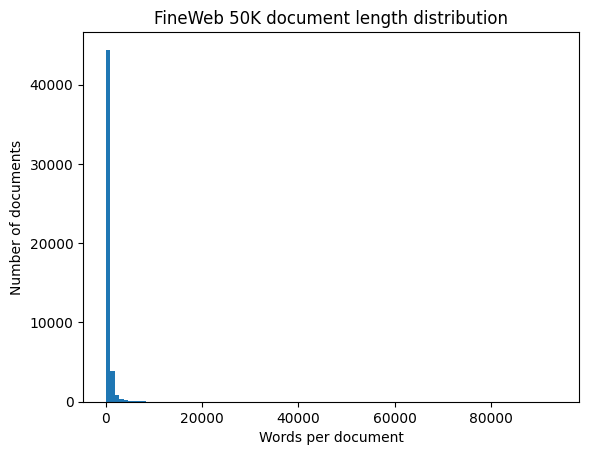

In [30]:
import matplotlib.pyplot as plt

plt.hist(word_lengths, bins=100)

plt.xlabel("Words per document")
plt.ylabel("Number of documents")
plt.title("FineWeb 50K document length distribution")

plt.show()

In [31]:
import numpy as np

lengths = np.array(word_lengths)

for p in [1, 5, 10, 25, 50, 75, 90, 95, 99, 99.5, 99.9]:
    print(f"{p:5.1f} percentile:", np.percentile(lengths, p))

print("\nMean:", lengths.mean())
print("Median:", np.median(lengths))
print("Min:", lengths.min())
print("Max:", lengths.max())


  1.0 percentile: 51.0
  5.0 percentile: 70.0
 10.0 percentile: 89.0
 25.0 percentile: 149.0
 50.0 percentile: 298.0
 75.0 percentile: 580.0
 90.0 percentile: 1020.0
 95.0 percentile: 1515.0
 99.0 percentile: 3711.210000000043
 99.5 percentile: 5589.009999999995
 99.9 percentile: 11280.055000000211

Mean: 519.0932
Median: 298.0
Min: 24
Max: 93587


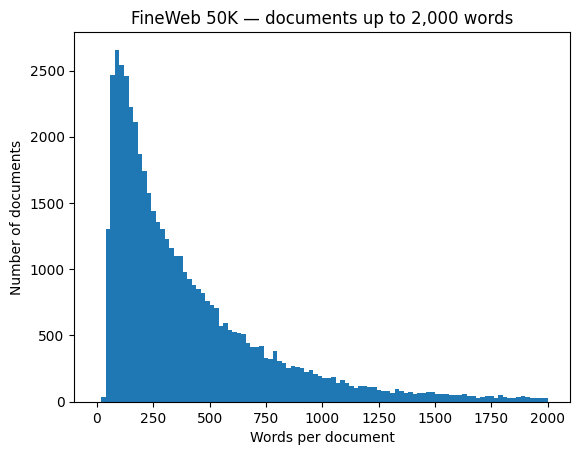

In [32]:
import matplotlib.pyplot as plt

plt.hist(
    word_lengths,
    bins=100,
    range=(0, 2000)
)

plt.xlabel("Words per document")
plt.ylabel("Number of documents")
plt.title("FineWeb 50K — documents up to 2,000 words")

plt.show()

In [21]:
short_docs = [row for row in dataset
    if len(row["text"].split()) <= 51]

print("Documents:", len(short_docs))

for i, row in enumerate(short_docs[:20]):
    print("=" * 100)
    print(f"DOCUMENT {i}")
    print(row["text"][:1500])

Documents: 520
DOCUMENT 0
Subject: Binary updates all installed pkgs? To: None <tech-pkg@NetBSD.org> From: Mark Weinem <firstname.lastname@example.org> List: tech-pkg Date: 02/21/2005 22:20:06
How to update all installed pkgs using binary packages? So, if my
installed packages are from ../packages/pkgsrc-2004Q3 how to update all
of them using the packages from .../packages/pkgsrc-2004Q4?
Regards, Mark Weinem
DOCUMENT 1
Olga Pretty Lace Cami Underwire Bra - #35263
That little extra.
How many times do you wish that you had something to wear under that low cut top but you don't want to wear another shirt under it. This product is the answer. Great idea...love it!
April 17, 2013
DOCUMENT 2
Short Dressesfrom £39
FURTHER REDUCTIONSShop All Sale
Jackets & Coatsfrom £35
Our New In pieces are perfect to keep your wardrobe refreshed.
Find a look you love in our latest lookbooks. Join the party on social media and get the lowdown on all things dressing up with our exclusive etiquette guides.
DOCU

In [33]:
long_docs = [row for row in dataset
    if len(row["text"].split()) >= 11280]

print("Documents:", len(long_docs))

for i, row in enumerate(long_docs[:10]):
    print("/n")
    print(f"DOCUMENT {i}")
    print(long_docs[i]["text"][:1500])

Documents: 51
/n
DOCUMENT 0
US 5396417 A
A data collection device and method, particularly for point-of-sale systems used in the sales and rental of merchandise including video records, and more particularly for a revenue-sharing video record rental system. In such a revenue-sharing system, both revenue-sharing records and ordinary merchandise can be sold using the same point-of-sale entry system. Data relating to the sales of rental of records is separated from the other data generated at the point-of-sale terminals by a data capture device, and the separated data is transmitted to a central computer where it is further processed to separate revenue-sharing record data from other record data, compute the shares due the store proprietor and the distributor of the revenue-sharing records, and for the performance of other functions. The data capture device is usable with a very wide variety of current point-of-sale computers and software so that the store owner can participate in the rev

In [34]:
def unique_word_ratio(text):
    words = text.lower().split()

    if not words:
        return 0

    return len(set(words)) / len(words)

In [35]:
ratios = [unique_word_ratio(row["text"])
    for row in dataset]

print("Minimum:", min(ratios))
print("Median:", np.median(ratios))
print("Mean:", np.mean(ratios))
print("10th percentile:", np.percentile(ratios, 10))
print("90th percentile:", np.percentile(ratios, 90))

Minimum: 0.13744687440852074
Median: 0.6120689655172413
Mean: 0.6157114356162284
10th percentile: 0.45977011494252873
90th percentile: 0.7808219178082192


In [36]:
!pip install -q ftfy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 1.7 MB/s eta 0:00:00


In [37]:
import re
import unicodedata
import ftfy


def normalize_text(text):

    text = ftfy.fix_text(text)
    text = unicodedata.normalize("NFKC", text)
    text = text.replace("\x00", "")
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [38]:
from urllib.parse import urlparse
import re


URL_PATTERN = re.compile(r"https?://\S+|www\.\S+",re.IGNORECASE)

def url_ratio(text):
    words = text.split()

    if not words:
        return 0

    urls = URL_PATTERN.findall(text)

    return len(urls) / len(words)

In [39]:
ratios = [
    url_ratio(row["text"])
    for row in dataset
]

print("P90:", np.percentile(ratios, 90))
print("P95:", np.percentile(ratios, 95))
print("P99:", np.percentile(ratios, 99))
print("Max:", max(ratios))

P90: 0.0
P95: 0.00216943317928886
P99: 0.009433962264150943
Max: 0.08484848484848485
